In [1]:
! pip install pandas numpy scikit-learn  shap matplotlib
! pip install shap  
! pip install lightgbm

'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.
'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.
'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


In [46]:
import pandas as pd
from constantes import (
    ENDERECO_DATASET_PENSE,
    ENDERECO_DICIONARIO_MICRODADOS_PENSE,
    ENDERECO_GERACAO_RESUMO_SIGNIFICADO_VARIAVEIS,
    ENDERECO_GERACAO_RESUMO_SIGNIFICADO_VARIAVEIS_DEPENDENTES,
    ENDERECO_GERACAO_RESUMO_SIGNIFICADO_VARIAVEIS_INDEPENDENTES,
    VARIAVEIS_DEPENDENTES,
    VARIAVEIS_INDEPENDENTES,
    NUMERO_CLASSES_POR_VARIAVEL_DEPENDENTE,
    NOVA_LINHA,
    COLUNA_PESO
)
from util import obter_descricao, carregar_mapa_codigos

In [47]:
#  Carregar o dataset normalizado
caminho = "../dados/em_processamento/dados_preparados_v2.txt"
dados_normalizados = pd.read_csv(caminho, sep=";", low_memory=False)

[LightGBM] [Info] Number of positive: 54492, number of negative: 45421
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.493709 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 99913, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494125 -> initscore=-0.023502
[LightGBM] [Info] Start training from score -0.023502
SHAP Values para a variável dependente: B12004 - Frequência de preocupação excessiva com coisas do cotidiano nos últimos 30 dias


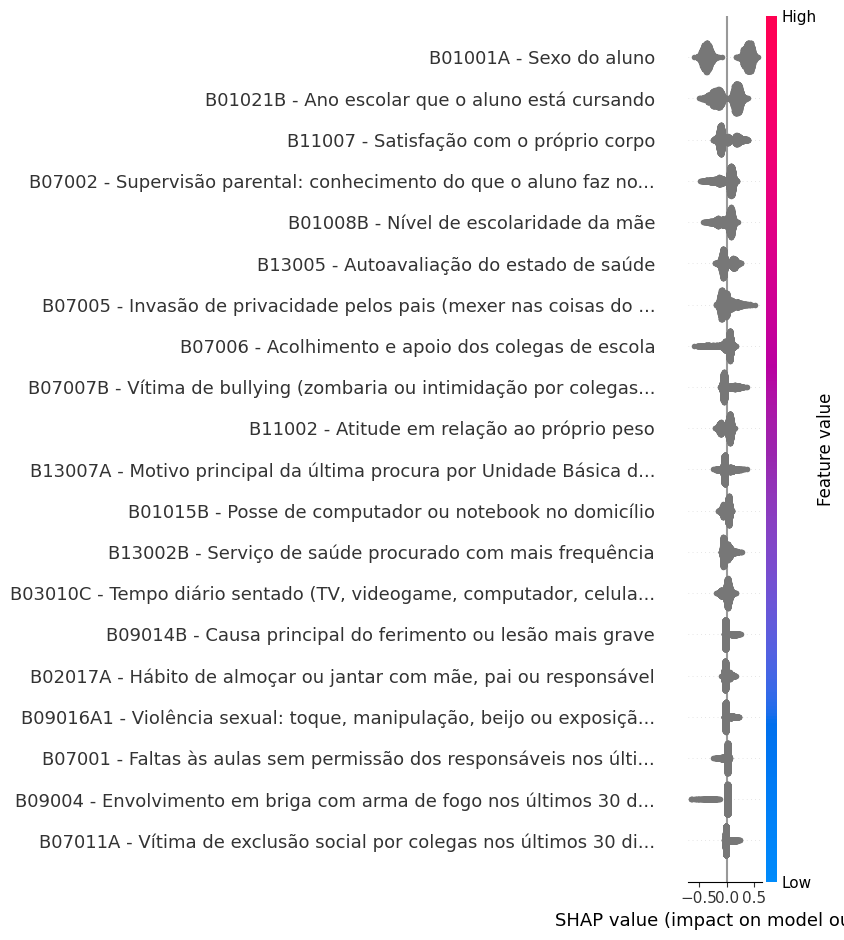

[LightGBM] [Info] Number of positive: 28923, number of negative: 70990
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.142186 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 99913, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.286982 -> initscore=-0.910089
[LightGBM] [Info] Start training from score -0.910089
SHAP Values para a variável dependente: B12005 - Frequência de tristeza nos últimos 30 dias


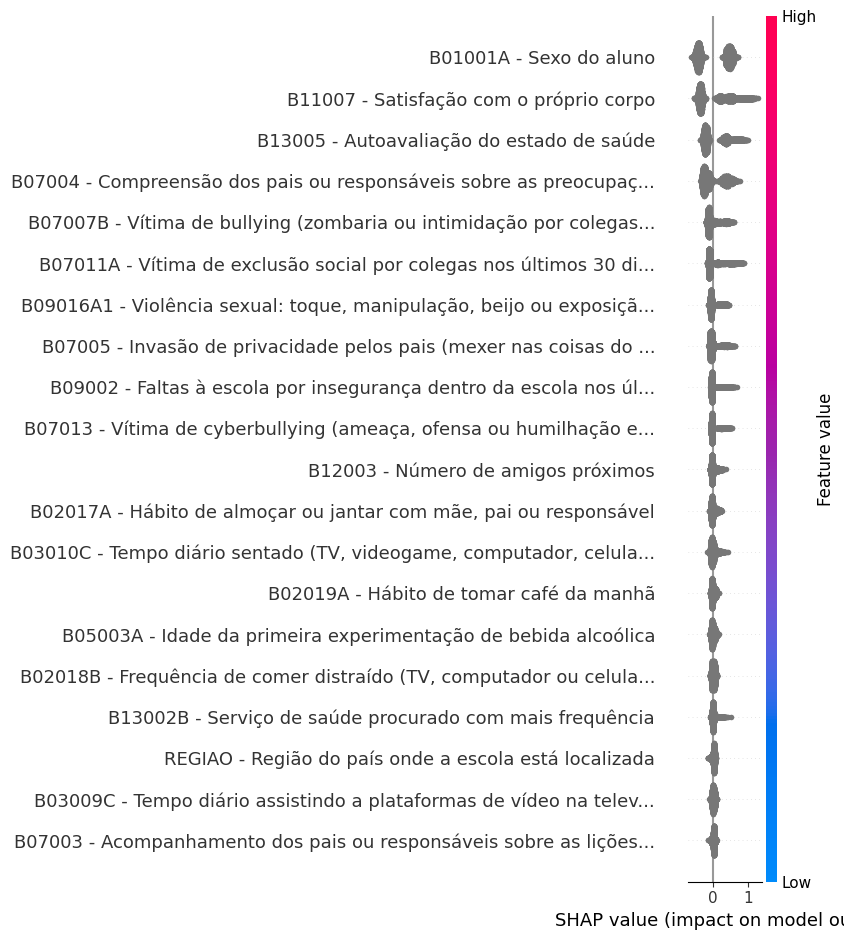

[LightGBM] [Info] Number of positive: 25404, number of negative: 74509
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.125661 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 99913, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.261207 -> initscore=-1.039703
[LightGBM] [Info] Start training from score -1.039703
SHAP Values para a variável dependente: B12006 - Frequência da sensação de que ninguém se preocupa com o aluno nos últimos 30 dias


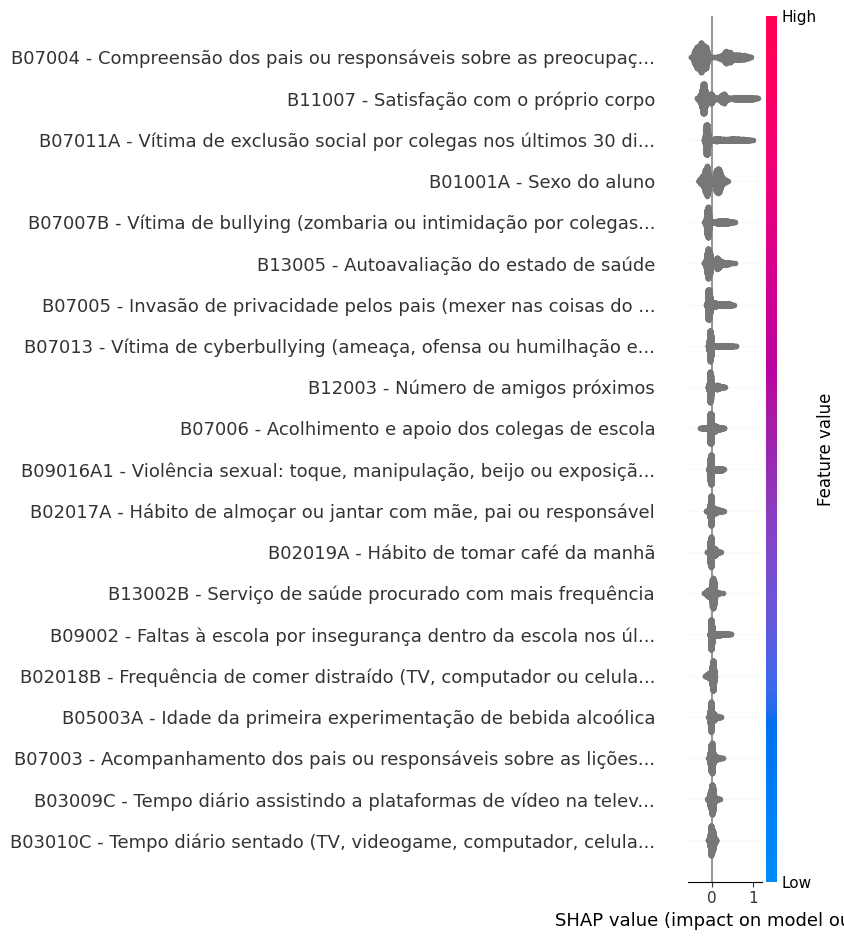

[LightGBM] [Info] Number of positive: 43384, number of negative: 56529
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.271737 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 99913, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.422435 -> initscore=-0.312784
[LightGBM] [Info] Start training from score -0.312784
SHAP Values para a variável dependente: B12007 - Frequência de irritação, nervosismo ou mau humor nos últimos 30 dias


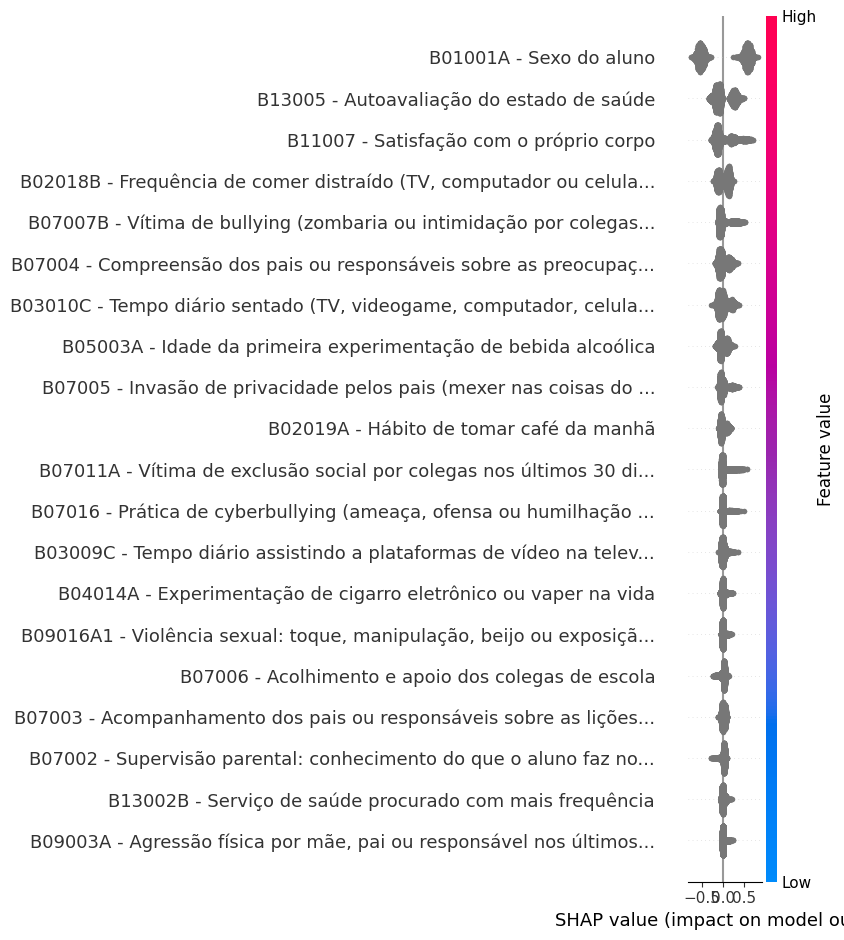

[LightGBM] [Info] Number of positive: 17811, number of negative: 82102
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.859353 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 99913, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.184915 -> initscore=-1.483394
[LightGBM] [Info] Start training from score -1.483394
SHAP Values para a variável dependente: B12008 - Frequência da sensação de que a vida não vale a pena ser vivida nos últimos 30 dias


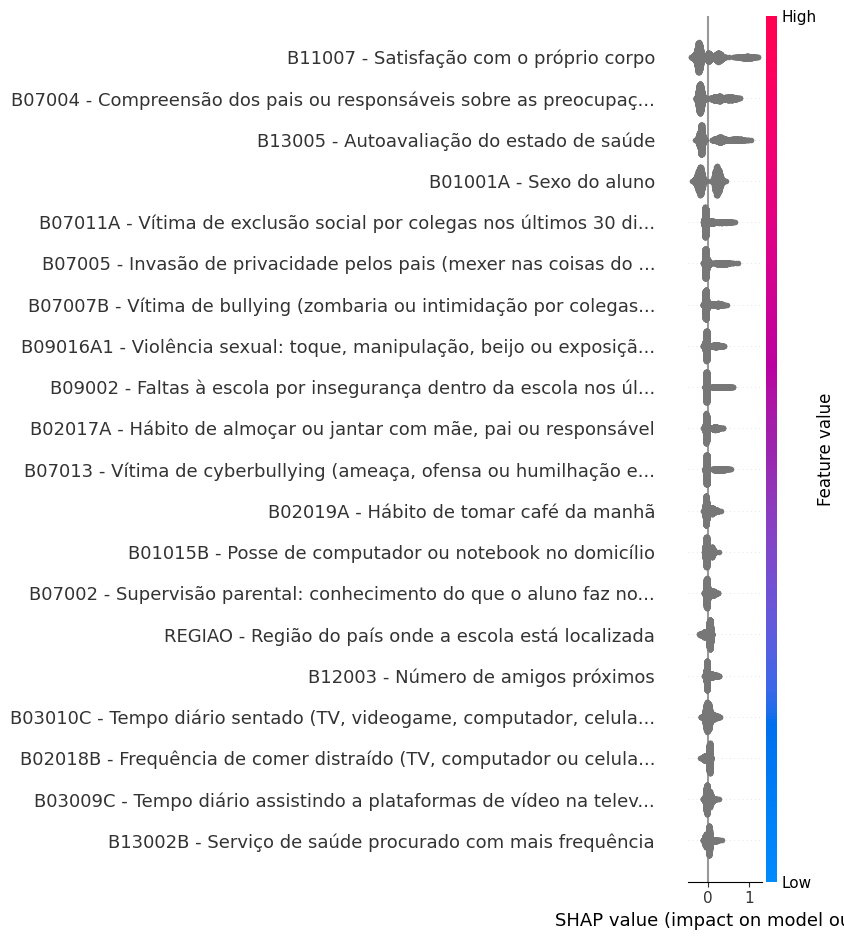

[LightGBM] [Warning] Contains only one class
[LightGBM] [Info] Number of positive: 0, number of negative: 99913
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.236509 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 99913, number of used features: 124
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.000000 -> initscore=-34.538776
[LightGBM] [Info] Start training from score -34.538776
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because t

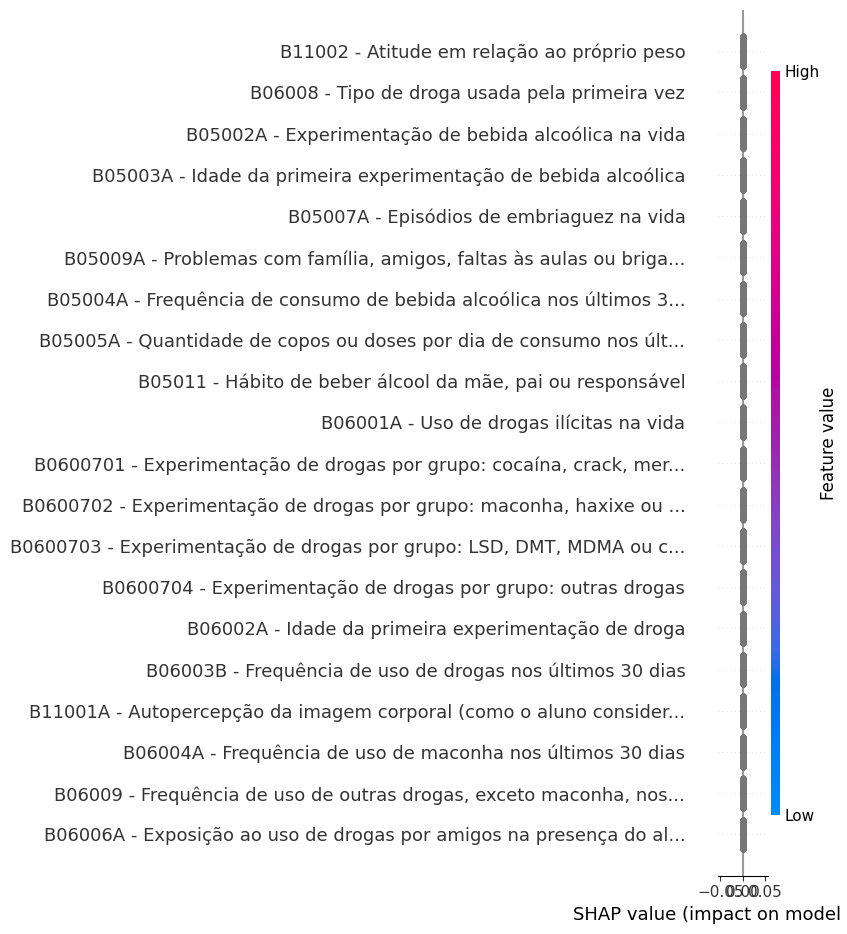

In [48]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import train_test_split

# le as variáveis pre definidas
colunas_explicativas = VARIAVEIS_INDEPENDENTES

for target in VARIAVEIS_DEPENDENTES:
  # Definir variável-alvo (Ex: 1 = sente-se sozinho frequentemente, 0 = raramente/nunca)
  # Substitua 'VAR_ALVO' pelo código real da pergunta no dicionário do IBGE
  df   = dados_normalizados.dropna(subset=[target])
  y = df[target].apply(lambda x: 1 if x in [4, 5] else 0)
  X = df[colunas_explicativas].copy()

  # Definir variáveis explicativas (Ex: bullying, horas de sono, atividade física) e o peso amostral
  pesos = df[COLUNA_PESO]  # Coluna de peso amostral da PeNSE

  # Converter variáveis categóricas para o tipo 'category' (o LightGBM lê nativamente)
  for col in colunas_explicativas:
    X[col] = X[col].astype('category')

  #  Dividir em treino e teste (mantendo os pesos alinhados)
  X_train, X_test, y_train, y_test, w_train, w_test = train_test_split( X, y, pesos, test_size=0.2, random_state=42)

  # Treinar o modelo LightGBM considerando o peso amostral 
  modelo = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, random_state=42)
  modelo.fit(X_train, y_train, sample_weight=w_train)

  # Extrair os SHAP Values
  explainer = shap.TreeExplainer(modelo)

  # Como a base da PeNSE é grande, pegue uma amostra (ex: 5.000 linhas) para rodar rápido
  X_amostra = X_test.sample(n=5000, random_state=42)
  shap_values = explainer(X_amostra)


  #lendo as descrições 
  nomes_descritivos = []
  for col in X_amostra.columns:
    desc = str(obter_descricao(col) or '')
    desc_curta = f'{desc[:55]}...' if len(desc) > 55 else desc
    nomes_descritivos.append(f'{col} - {desc_curta}' if desc else col)

  # Atualiza os nomes diretamente dentro do objeto shap_values
  shap_values.feature_names = nomes_descritivos

  # Visualizar os resultados (Gráfico Beeswarm)
  print(f"SHAP Values para a variável dependente: {target} - {obter_descricao(target)}")
  plt.figure(figsize=(10, 8))
 # shap.summary_plot(shap_values, X_amostra)
  shap.summary_plot(shap_values, X_amostra)
  #print(X_amostra_desc)

In [38]:
#print(X_amostra_desc)

       B01001A - Sexo do aluno  \
59564                      1.0   
2323                       1.0   
66869                      2.0   
31009                      2.0   
38001                      2.0   
...                        ...   
49617                      2.0   
122747                     1.0   
105092                     1.0   
40137                      2.0   
65340                      2.0   

       REGIAO - Região do país onde a escola está localizada  \
59564                                                   2      
2323                                                    1      
66869                                                   2      
31009                                                   2      
38001                                                   2      
...                                                   ...      
49617                                                   2      
122747                                                  5      
105092         